# 05 · The default model: full run R01 and a look at what it learned (tasks T17 and T18)

R01 is the main model and the reference that every ablation is compared with:
MobileNetV2 encoder (random initial weights), VV + VH + ratio input, BCE + Dice loss, seed 0.

* **T17**: train for up to 60 epochs with learning-rate reduction and early stopping on the validation water IoU, and keep the best-validation model.
* **T18**: inspect the training curves and the predictions **on validation chips only**, and write down what they show, before the training defaults are frozen.

**Test and Bolivia are not opened in this notebook.** R01 is scored on them only after the defaults are frozen (task T19), in notebook 06, so that no test number exists while the method can still change.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import viz
from src.config import load_config, run_dir
from src.runner import run_training

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
RUN = "R01"
cfg = load_config(RUN)
pd.Series(cfg, name=RUN).to_frame()

,R01
run_id,R01
config_name,Default
study,"E1, E2, E3 (shared)"
encoder,mobilenetv2
channels,vv_vh_ratio
loss,bce_dice
seed,0
optimizer,adam
learning_rate,0.0010
batch_size,8


## 1. Train (T17)

Callbacks, all watching the **validation water IoU**: keep the best model, halve the learning rate after 5 epochs without improvement, stop after 15 epochs without improvement.

In [2]:
metrics = run_training(RUN, evaluate=False)

[R01 was trained on 2026-11-11 12:03 UTC; this is its saved log]
R01: Default | encoder mobilenetv2 | channels vv_vh_ratio | loss bce_dice | seed 0 | 5,419,473 parameters | mixed_float16
epoch  1/60 | loss 1.0625  iou 0.3772 | val_loss 1.1750  val_iou 0.3980 | lr 1.0e-03 |  61.2s *
epoch  2/60 | loss 0.8621  iou 0.4306 | val_loss 0.9782  val_iou 0.3569 | lr 1.0e-03 |   8.4s
epoch  3/60 | loss 0.7525  iou 0.4632 | val_loss 0.7335  val_iou 0.3933 | lr 1.0e-03 |   8.3s
epoch  4/60 | loss 0.6945  iou 0.4865 | val_loss 0.5425  val_iou 0.5857 | lr 1.0e-03 |   8.3s *
epoch  5/60 | loss 0.6865  iou 0.4653 | val_loss 0.4891  val_iou 0.5989 | lr 1.0e-03 |   8.5s *
epoch  6/60 | loss 0.6788  iou 0.4823 | val_loss 0.5437  val_iou 0.5743 | lr 1.0e-03 |   8.5s
epoch  7/60 | loss 0.6673  iou 0.4814 | val_loss 0.8186  val_iou 0.3705 | lr 1.0e-03 |   8.4s
epoch  8/60 | loss 0.6260  iou 0.5269 | val_loss 0.4577  val_iou 0.6202 | lr 1.0e-03 |   8.4s *
epoch  9/60 | loss 0.6321  iou 0.5173 | val_loss 0.48

In [3]:
t = metrics["training"]
pd.Series({
    "epochs trained (of at most 60)": t["epochs_trained"],
    "best epoch": t["best_epoch"],
    "stopped early": t["stopped_early"],
    "learning rate at the end": t["final_learning_rate"],
    "seconds per epoch": t["sec_per_epoch"],
    "training time (min)": t["train_minutes"],
    "peak GPU memory (MB)": t["peak_gpu_memory_mb"],
    "peak host RAM (MB)": t.get("peak_host_ram_mb"),
    "parameters": t["parameters"],
}, name=RUN).to_frame()

,R01
epochs trained (of at most 60),39
best epoch,24
stopped early,True
learning rate at the end,0.0001
seconds per epoch,8.6400
training time (min),6.8600
peak GPU memory (MB),622.5000
peak host RAM (MB),4104
parameters,5419473


## 2. Training curves (T18)

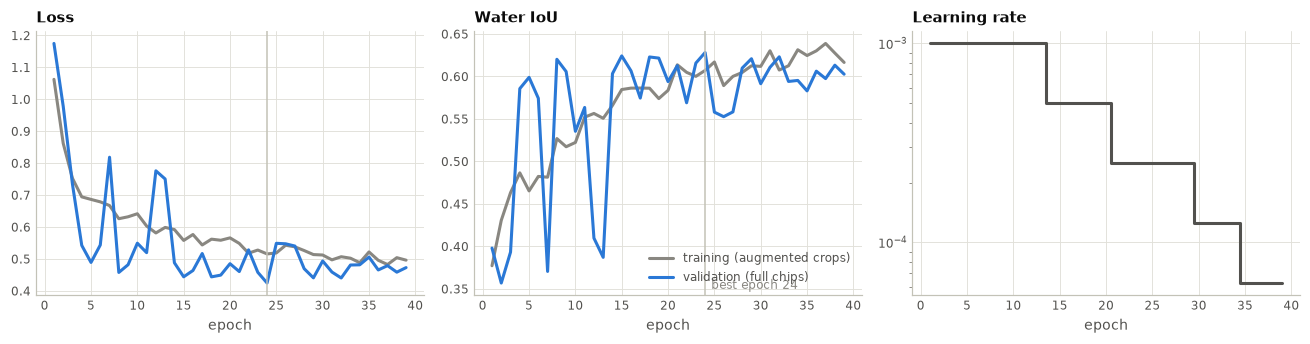

In [4]:
history = pd.read_csv(run_dir(RUN) / "history.csv")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
viz.plot_history(history, axes[:2], best_epoch=t["best_epoch"])
axes[2].step(history["epoch"] + 1, history["learning_rate"], where="mid", color=viz.INK_2)
axes[2].set_yscale("log")
axes[2].set_xlabel("epoch")
axes[2].set_title("Learning rate")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "R01_training_curves.png")
plt.show()

In [5]:
best = history.loc[history["val_water_iou"].idxmax()]
last5 = history.tail(5)
pd.Series({
    "best validation IoU": best["val_water_iou"],
    "training IoU at that epoch (augmented crops)": best["water_iou"],
    "validation loss at the best epoch": best["val_loss"],
    "lowest validation loss (epoch %d)" % (history["val_loss"].idxmin() + 1): history["val_loss"].min(),
    "training loss, last 5 epochs (mean)": last5["loss"].mean(),
    "validation loss, last 5 epochs (mean)": last5["val_loss"].mean(),
    "validation IoU, last 5 epochs (mean)": last5["val_water_iou"].mean(),
    "validation IoU: std over the last 10 epochs": history["val_water_iou"].tail(10).std(),
}, name=RUN).to_frame()

,R01
best validation IoU,0.6282
training IoU at that epoch (augmented crops),0.6071
validation loss at the best epoch,0.4245
lowest validation loss (epoch 24),0.4245
"training loss, last 5 epochs (mean)",0.5001
"validation loss, last 5 epochs (mean)",0.4764
"validation IoU, last 5 epochs (mean)",0.6005
validation IoU: std over the last 10 epochs,0.0119


## 3. Validation scores, next to the Otsu baseline on the same chips

In [6]:
otsu = json.loads((run_dir("R00") / "metrics.json").read_text())["val"]
val = metrics["val"]
cols = {"water IoU (pooled)": "iou", "precision": "precision", "recall": "recall", "F1": "f1", "mean per-chip IoU": "mean_chip_iou"}
pd.DataFrame({"Otsu on VH (R00)": {k: otsu[v] for k, v in cols.items()},
              "Default U-Net (R01)": {k: val[v] for k, v in cols.items()}}).T

,water IoU (pooled),precision,recall,F1,mean per-chip IoU
Otsu on VH (R00),0.3880,0.4265,0.8110,0.5591,0.2642
Default U-Net (R01),0.6282,0.8509,0.7059,0.7716,0.3760


In [7]:
chips = pd.read_csv(run_dir(RUN) / "per_chip.csv")
chips = chips[chips["split"] == "val"].copy()
otsu_chips = pd.read_csv(run_dir("R00") / "per_chip.csv")
otsu_chips = otsu_chips[otsu_chips["split"] == "val"].set_index("chip")
chips["otsu_iou"] = chips["chip"].map(otsu_chips["iou"])

by_event = chips.groupby("event").agg(chips=("chip", "size"), tp=("tp", "sum"), fp=("fp", "sum"), fn=("fn", "sum"),
                                      water_px=("n_water", "sum"))
by_event["U-Net IoU"] = by_event["tp"] / (by_event["tp"] + by_event["fp"] + by_event["fn"])
o = otsu_chips.groupby("event")[["tp", "fp", "fn"]].sum()
by_event["Otsu IoU"] = o["tp"] / (o["tp"] + o["fp"] + o["fn"])
by_event["precision"] = by_event["tp"] / (by_event["tp"] + by_event["fp"])
by_event["recall"] = by_event["tp"] / (by_event["tp"] + by_event["fn"])
by_event[["chips", "water_px", "Otsu IoU", "U-Net IoU", "precision", "recall"]].sort_values("U-Net IoU")

,chips,water_px,Otsu IoU,U-Net IoU,precision,recall
event,,,,,,
Somalia,5,42627,0.0711,0.0878,0.2330,0.1234
Ghana,11,261548,0.5264,0.4629,0.9815,0.4670
Paraguay,14,372233,0.3999,0.4759,0.8356,0.5251
Pakistan,6,78903,0.2019,0.4768,0.5203,0.8507
India,14,441798,0.5480,0.6472,0.8440,0.7352
USA,14,110589,0.1526,0.6531,0.8631,0.7286
Sri-Lanka,9,175035,0.3346,0.6646,0.9334,0.6977
Spain,6,277646,0.4658,0.7538,0.8332,0.8878
Nigeria,4,269763,0.6516,0.7932,0.9381,0.8370


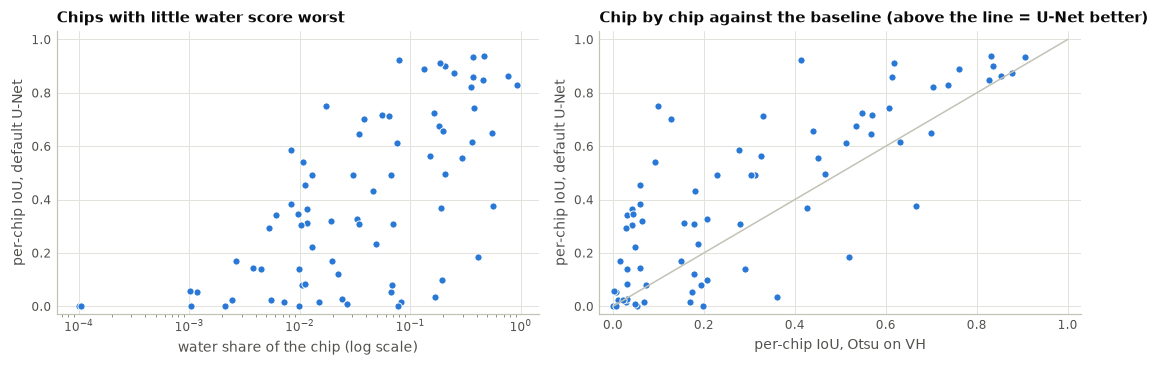

validation chips with water: 77 | U-Net better than Otsu on 54 of them
validation chips without water: 12 | U-Net predicts no water at all on 8, median false-alarm pixels on the others: 90.5


In [8]:
with_water = chips[chips["n_water"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].scatter(with_water["water_frac"].clip(lower=1e-4), with_water["iou"], s=22, color=viz.BLUE, edgecolor="white", linewidth=0.6)
axes[0].set_xscale("log")
axes[0].set_xlabel("water share of the chip (log scale)")
axes[0].set_ylabel("per-chip IoU, default U-Net")
axes[0].set_ylim(-0.03, 1.03)
axes[0].set_title("Chips with little water score worst")

axes[1].scatter(with_water["otsu_iou"], with_water["iou"], s=22, color=viz.BLUE, edgecolor="white", linewidth=0.6)
axes[1].plot([0, 1], [0, 1], color=viz.AXIS, linewidth=1)
axes[1].set_xlabel("per-chip IoU, Otsu on VH")
axes[1].set_ylabel("per-chip IoU, default U-Net")
axes[1].set_xlim(-0.03, 1.03)
axes[1].set_ylim(-0.03, 1.03)
axes[1].set_title("Chip by chip against the baseline (above the line = U-Net better)")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "R01_val_per_chip.png")
plt.show()

no_water = chips[chips["n_water"] == 0]
print(f"validation chips with water: {len(with_water)} | U-Net better than Otsu on {(with_water['iou'] > with_water['otsu_iou']).sum()} of them")
print(f"validation chips without water: {len(no_water)} | U-Net predicts no water at all on {(no_water['fp'] == 0).sum()}, "
      f"median false-alarm pixels on the others: {no_water.loc[no_water['fp'] > 0, 'fp'].median()}")

## 4. Predictions on validation chips (T18)

Six validation chips chosen by a fixed rule from the chips with at least 1% water: the two with the lowest IoU, the two around the median, and the two with the highest.
Columns: VH, the hand label, and the prediction coloured by outcome.

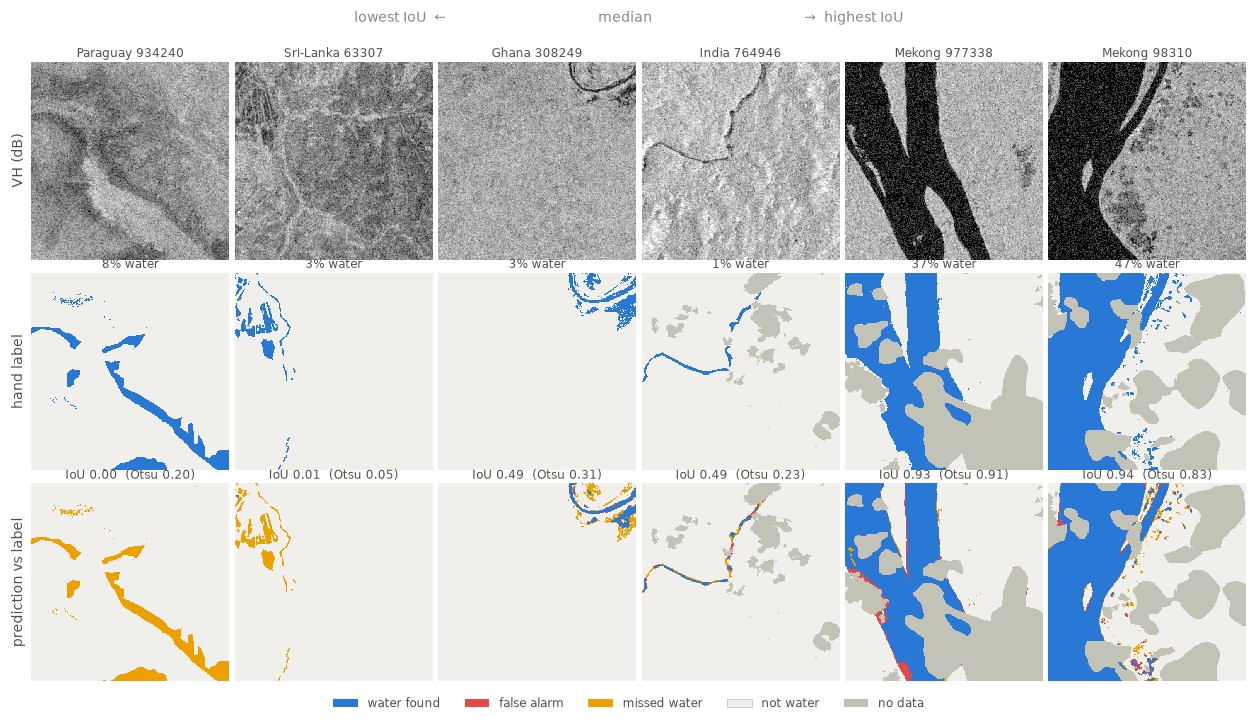

In [9]:
from src.data import load_split
from src.evaluate import load_run_model, predict_proba
from src.pipeline import load_arrays
from src.train import setup_runtime

setup_runtime(cfg["mixed_precision"])
model = load_run_model(RUN)
model.jit_compile = False   # a handful of chips: the plain graph is fast enough and needs no compiling
val_data = load_split("val")
X_val, _ = load_arrays("val", cfg["channels"])
probs = predict_proba(model, X_val, cfg["eval_batch_size"])
pred = probs >= cfg["threshold"]

ranked = chips[chips["water_frac"] >= 0.01].sort_values("iou").reset_index(drop=True)
mid = len(ranked) // 2
picks = pd.concat([ranked.iloc[:2], ranked.iloc[mid - 1:mid + 1], ranked.iloc[-2:]])
index = {n: i for i, n in enumerate(val_data.names)}

fig, axes = plt.subplots(3, 6, figsize=(11.5, 6.3))
for col, (_, row) in enumerate(picks.iterrows()):
    i = index[row["chip"]]
    viz.show_db(axes[0, col], val_data.images[i, 1], "VH", title=row["chip"].replace("_", " "))
    viz.show_label(axes[1, col], val_data.labels[i], title=f"{row['water_frac']:.0%} water")
    viz.show_errors(axes[2, col], pred[i], val_data.labels[i], title=f"IoU {row['iou']:.2f}  (Otsu {row['otsu_iou']:.2f})")
for r, text in enumerate(("VH (dB)", "hand label", "prediction vs label")):
    axes[r, 0].set_ylabel(text, fontsize=9, color=viz.INK_2)
fig.legend(handles=viz.error_legend_handles(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("lowest IoU  ←                                      median                                      →  highest IoU",
             fontsize=9, color=viz.MUTED, y=0.995)
fig.tight_layout(h_pad=0.5, w_pad=0.4)
viz.savefig(fig, ROOT / "figures" / "R01_val_predictions.png")
plt.show()

## 5. Is 0.5 a sensible threshold? (validation only)

The plan fixes the decision threshold at 0.5. This check only asks whether that is unreasonable for this model; it does not tune anything.

In [10]:
labels = val_data.labels
valid, truth = labels != -1, labels == 1
rows = []
for thr in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
    p = probs >= thr
    tp, fp, fn = int((p & truth).sum()), int((p & valid & ~truth).sum()), int((~p & truth).sum())
    rows.append({"threshold": thr, "IoU": tp / (tp + fp + fn), "precision": tp / (tp + fp), "recall": tp / (tp + fn)})
thr_table = pd.DataFrame(rows).set_index("threshold")
thr_table.to_csv(run_dir(RUN) / "val_threshold_check.csv")
confident = float(((probs < 0.05) | (probs > 0.95))[valid].mean())
print(f"share of validation pixels with a probability below 0.05 or above 0.95: {confident:.1%}")
thr_table.T

share of validation pixels with a probability below 0.05 or above 0.95: 92.7%


threshold,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000
IoU,0.6436,0.6436,0.6383,0.6332,0.6282,0.6224,0.6147,0.6008,0.5590
precision,0.7682,0.8060,0.8254,0.8389,0.8509,0.8622,0.8744,0.8906,0.9232
recall,0.7986,0.7616,0.7380,0.7208,0.7059,0.6911,0.6742,0.6487,0.5862


## 6. What the curves and the pictures show (T18)

1. **No overfitting.** The training loss falls steadily to about 0.50 and the validation loss stays at or below it. Training IoU (on augmented crops) and validation IoU end at the same level, a little above 0.6. The model is limited by the data, not memorising it.
2. **The validation score is noisy.** At the starting learning rate it swings by up to 0.25 IoU from one epoch to the next (0.57 → 0.37 → 0.62 in epochs 6 to 8). After the learning-rate drops it settles into a band about 0.03 wide; the best epoch (24, IoU 0.628) is a peak inside that band. A single run therefore cannot resolve differences of one or two IoU points between configs, which is exactly why every config is run with three seeds.
3. **A clear step up from thresholding** on the same validation chips: pooled IoU 0.63 against 0.39 for Otsu and 0.49 for the threshold tuned on the training labels; better than Otsu on 54 of the 77 chips that contain water. On the 12 chips without water it predicts no water at all on 8.
4. **It errs on the side of missing water.** Precision is 0.85 and recall 0.71. Predictions are smooth and coherent, neither blocky nor speckled, and false alarms are rare. Large open water is mapped almost perfectly (IoU 0.93 to 0.94, errors only along the shoreline); thin rivers and small ponds are partly missed (IoU about 0.5). The two worst chips are places where the labelled water has no dark signature in the radar image at all, so the model, reasonably, predicts nothing there.
5. **Events differ a lot.** Pooled IoU per event runs from 0.87 (Mekong) and 0.79 (Nigeria) down to about 0.47 (Paraguay, Pakistan, Ghana) and 0.09 (Somalia, which has very little water). In Ghana the U-Net is below Otsu: almost everything it marks is water (precision 0.98) but it finds under half of it.
6. **The 0.5 threshold is slightly conservative.** A threshold of 0.1 to 0.2 would give a validation IoU of 0.644 instead of 0.628. The plan fixes 0.5 for every model, so this is left as it is and listed as a limitation; 93% of the pixels have a probability below 0.05 or above 0.95, so the choice matters only for a thin band of uncertain pixels.

## 7. Decision

No bug and no sign of a broken training set-up was found, so **nothing is changed**. The settings R01 was trained with become the frozen defaults (`src/config_default.json`, git tag `defaults-frozen`, task T19). R01 is scored on test and Bolivia in notebook 06, once, after the freeze.